# 02 — Imagery Preprocessing

This notebook preprocesses **one selected Sentinel-2 L2A scene** for the
**Mombasa test area** (Nyali–Bamburi–Shanzu coastline, Kenya). It is the
first step of the ShoreMonitor imagery pipeline: set up paths, then in later
cells clip, cloud-mask, and derive water indices / water masks for a single
tile before scaling to the full time series.

The first cell only configures the environment and project paths — it does
not download or process any imagery.

In [11]:
import sys
from pathlib import Path

# The notebook lives in notebooks/, so the project root is one level up.
project_root = Path.cwd().parent
if str(project_root) not in sys.path:
    sys.path.append(str(project_root))

import json
import numpy as np
import pandas as pd
import geopandas as gpd
import rasterio
import rioxarray as rxr
import xarray as xr
import planetary_computer as pc
import pystac_client

# --- Project paths (all derived from the project root) ------------------------
PROJECT_ROOT = project_root
CONFIG_DIR = PROJECT_ROOT / "config"
DATA_DIR = PROJECT_ROOT / "data"
RAW_DIR = DATA_DIR / "raw"
INTERIM_DIR = DATA_DIR / "interim"
PROCESSED_DIR = DATA_DIR / "processed"
TEST_DIR = INTERIM_DIR / "mombasa_test"

# --- Create the test-area output folders -------------------------------------
for folder in (
    TEST_DIR,
    TEST_DIR / "clipped",
    TEST_DIR / "masked",
    TEST_DIR / "water_index",
    TEST_DIR / "water_mask",
):
    folder.mkdir(parents=True, exist_ok=True)

# --- Inputs and Planetary Computer STAC configuration -------------------------
STUDY_AREA_PATH = CONFIG_DIR / "study_area.geojson"
SCENE_CATALOG_PATH = RAW_DIR / "sentinel-2" / "sentinel2_scene_catalog_2024.csv"
STAC_URL = "https://planetarycomputer.microsoft.com/api/stac/v1"
SENTINEL2_COLLECTION = "sentinel-2-l2a"

print("Project root:      ", PROJECT_ROOT)
print("Study area:        ", STUDY_AREA_PATH)
print("Scene catalog:     ", SCENE_CATALOG_PATH)
print("Test output folder:", TEST_DIR)

Project root:       c:\Users\pc\Documents\Data Science Projects\Shoremonitor
Study area:         c:\Users\pc\Documents\Data Science Projects\Shoremonitor\config\study_area.geojson
Scene catalog:      c:\Users\pc\Documents\Data Science Projects\Shoremonitor\data\raw\sentinel-2\sentinel2_scene_catalog_2024.csv
Test output folder: c:\Users\pc\Documents\Data Science Projects\Shoremonitor\data\interim\mombasa_test


## Study area and scene catalog

The **study area** (`config/study_area.geojson`) defines the spatial extent of
the analysis — every scene is clipped to this polygon before any processing.

The **scene catalog** (`sentinel2_scene_catalog_2024.csv`), produced by
Notebook 01, lists the available Sentinel-2 L2A scenes (scene ID, datetime,
cloud cover, MGRS tile, platform) that intersect the study area. This cell
loads and inspects both inputs; it does not query Planetary Computer,
download, or process any imagery.

In [12]:
# --- Load and normalise the study area ---------------------------------------
if not STUDY_AREA_PATH.exists():
    raise FileNotFoundError(f"Study-area file not found: {STUDY_AREA_PATH}")

study_area = gpd.read_file(STUDY_AREA_PATH)

# Reproject to WGS84 (EPSG:4326) if the CRS is missing or different.
if study_area.crs is None or study_area.crs.to_epsg() != 4326:
    study_area = study_area.to_crs(epsg=4326)

# Bounding box for the STAC search: [minx, miny, maxx, maxy].
study_area_bounds = study_area.total_bounds
bbox = [
    float(study_area_bounds[0]),
    float(study_area_bounds[1]),
    float(study_area_bounds[2]),
    float(study_area_bounds[3]),
]

# --- Load and sort the scene catalog -----------------------------------------
if not SCENE_CATALOG_PATH.exists():
    raise FileNotFoundError(f"Scene catalog not found: {SCENE_CATALOG_PATH}")

scene_catalog = pd.read_csv(SCENE_CATALOG_PATH)
scene_catalog["datetime"] = pd.to_datetime(scene_catalog["datetime"])
scene_catalog = scene_catalog.sort_values("datetime").reset_index(drop=True)

# --- Inspect -----------------------------------------------------------------
print("Study area:")
print(study_area)
print("\nBounding box [minx, miny, maxx, maxy]:")
print(bbox)
print(f"\nNumber of scenes in catalog: {len(scene_catalog)}")
print("\nFirst five scenes:")
print(scene_catalog.head())

Study area:
                           name country    analysis_level  \
0  Mombasa-Nyali-Bamburi-Shanzu   Kenya  detailed_hotspot   

                                            geometry  
0  POLYGON ((39.65 -4.1, 39.85 -4.1, 39.85 -3.9, ...  

Bounding box [minx, miny, maxx, maxy]:
[39.65, -4.1, 39.85, -3.9]

Number of scenes in catalog: 8

First five scenes:
                                            scene_id  \
0  S2A_MSIL2A_20240310T072721_R049_T37MER_2024031...   
1  S2A_MSIL2A_20240310T072721_R049_T37MER_2024031...   
2  S2B_MSIL2A_20240325T072619_R049_T37MER_2024032...   
3  S2A_MSIL2A_20240529T074541_R049_T37MER_2024052...   
4  S2B_MSIL2A_20240613T072619_R049_T37MER_2024061...   

                       datetime  cloud_cover mgrs_tile     platform  \
0 2024-03-10 07:27:21.024+00:00    19.834769     37MER  Sentinel-2A   
1 2024-03-10 07:27:21.024+00:00    19.834769     37MER  Sentinel-2A   
2 2024-03-25 07:26:19.024+00:00     9.632075     37MER  Sentinel-2B   
3 2024-05-29 07

## Select a test scene

To keep the first pass simple, we preprocess a **single scene** rather than
the full time series. We pick the **clearest available 2024 scene** — the
one with the lowest `eo:cloud_cover` — from the catalog produced by Notebook
01. This cell only reads and filters the catalog; it does not connect to
Planetary Computer, download imagery, or process pixels.

In [13]:
# --- Filter to 2024 scenes ----------------------------------------------------
scene_catalog["datetime"] = pd.to_datetime(scene_catalog["datetime"])
scenes_2024 = scene_catalog[
    (scene_catalog["datetime"] >= "2024-01-01")
    & (scene_catalog["datetime"] < "2025-01-01")
].copy()

if scenes_2024.empty:
    raise ValueError(
        "No 2024 scenes found in the catalog. "
        f"Catalog range: {scene_catalog['datetime'].min()} to "
        f"{scene_catalog['datetime'].max()}."
    )

# --- Pick the clearest scene (lowest cloud cover) -----------------------------
scenes_2024 = scenes_2024.sort_values("cloud_cover", ascending=True)
selected_scene = scenes_2024.iloc[0]

selected_scene_id = selected_scene["scene_id"]
selected_scene_datetime = selected_scene["datetime"]
selected_scene_cloud_cover = selected_scene["cloud_cover"]
selected_scene_mgrs_tile = selected_scene["mgrs_tile"]
selected_scene_platform = selected_scene["platform"]

print("Selected test scene:")
print("  scene_id:   ", selected_scene_id)
print("  datetime:   ", selected_scene_datetime)
print("  cloud_cover:", selected_scene_cloud_cover)
print("  mgrs_tile:  ", selected_scene_mgrs_tile)
print("  platform:   ", selected_scene_platform)

# --- Persist the selected scene metadata --------------------------------------
selected_scene_path = TEST_DIR / "selected_scene_metadata.csv"
selected_scene.to_frame().T.to_csv(selected_scene_path, index=False)
print("\nSaved selected scene metadata to:", selected_scene_path)

Selected test scene:
  scene_id:    S2A_MSIL2A_20240529T074541_R049_T37MER_20240529T123614
  datetime:    2024-05-29 07:45:41.024000+00:00
  cloud_cover: 0.122262
  mgrs_tile:   37MER
  platform:    Sentinel-2A

Saved selected scene metadata to: c:\Users\pc\Documents\Data Science Projects\Shoremonitor\data\interim\mombasa_test\selected_scene_metadata.csv


## Retrieve STAC metadata for the selected scene

This cell connects to **Microsoft Planetary Computer**, searches the
`sentinel-2-l2a` collection for the chosen `selected_scene_id`, and keeps
the single matching **STAC item**. The item carries the scene metadata and
the (signable) asset URLs used in later cells. No raster data is loaded,
clipped, or processed here.

In [14]:
# --- Connect to the Planetary Computer STAC API -------------------------------
stac_api = pystac_client.Client.open(
    STAC_URL,
    modifier=pc.sign_inplace,
)

# --- Search for the selected scene by ID --------------------------------------
search = stac_api.search(
    collections=[SENTINEL2_COLLECTION],
    ids=[selected_scene_id],
)
matching_items = list(search.items())

if not matching_items:
    raise ValueError(
        f"No STAC item found for scene ID '{selected_scene_id}' "
        f"in collection '{SENTINEL2_COLLECTION}'."
    )

# Keep the item whose id exactly matches the selected scene.
selected_item = next(
    (item for item in matching_items if item.id == selected_scene_id),
    matching_items[0],
)

# --- Inspect the item ---------------------------------------------------------
print("Item ID:        ", selected_item.id)
print("Datetime:       ", selected_item.datetime)
print("Cloud cover:    ", selected_item.properties.get("eo:cloud_cover"))
print("MGRS tile:      ", selected_item.properties.get("s2:mgrs_tile"))
print("\nAvailable assets:")
for asset_key in sorted(selected_item.assets.keys()):
    print(" ", asset_key)

# --- Verify required assets are present ---------------------------------------
REQUIRED_ASSETS = ["B03", "B11", "SCL"]
missing_assets = [key for key in REQUIRED_ASSETS if key not in selected_item.assets]
if missing_assets:
    raise ValueError(
        "Selected item is missing required asset(s): " + ", ".join(missing_assets) + "."
    )

print("\nAll required assets present:", REQUIRED_ASSETS)

Item ID:         S2A_MSIL2A_20240529T074541_R049_T37MER_20240529T123614
Datetime:        2024-05-29 07:45:41.024000+00:00
Cloud cover:     0.122262
MGRS tile:       37MER

Available assets:
  AOT
  B01
  B02
  B03
  B04
  B05
  B06
  B07
  B08
  B09
  B11
  B12
  B8A
  SCL
  WVP
  datastrip-metadata
  granule-metadata
  inspire-metadata
  preview
  product-metadata
  rendered_preview
  safe-manifest
  tilejson
  visual

All required assets present: ['B03', 'B11', 'SCL']


## Load the required Sentinel-2 bands

For the MNDWI calculation we need two surface-reflectance bands:

- **B03** (green, 10 m)
- **B11** (shortwave infrared / SWIR, 20 m)

and the **SCL** (Scene Classification Layer, 20 m), which flags clouds,
cloud shadows, and invalid pixels so they can be masked later.

Each asset is opened at its **native resolution** with `rioxarray` (note
B03 is 10 m while B11 and SCL are 20 m). Nothing is clipped, masked,
resampled, or saved in this cell — that happens in later steps.

In [15]:
# --- Open the required assets at native resolution ----------------------------
# Planetary Computer assets require a signed URL before they can be read.
def open_asset(asset_key, var_name):
    """Open a STAC asset as a single-band rioxarray DataArray (masked+scaled)."""
    href = pc.sign(selected_item.assets[asset_key].href)
    da = rxr.open_rasterio(
        href,
        masked=True,
        mask_and_scale=True,
    )
    if da.rio.count > 1:  # keep only the first band if multi-band
        da = da.isel(band=0)
    else:
        da = da.squeeze(drop=True)
    return da


green_da = open_asset("B03", "green")  # 10 m
swir_da = open_asset("B11", "swir")  # 20 m
scl_da = open_asset("SCL", "scl")  # 20 m (scene classification)

# --- Inspect each band --------------------------------------------------------
for asset_name, da in [
    ("B03 (green)", green_da),
    ("B11 (SWIR)", swir_da),
    ("SCL", scl_da),
]:
    res_x, res_y = da.rio.resolution()
    print(f"{asset_name}:")
    print(f"  shape:          {tuple(da.shape)}")
    print(f"  CRS:            {da.rio.crs}")
    print(f"  resolution:     x={res_x}, y={res_y}")
    print(f"  min value:      {float(da.min().compute()):.2f}")
    print(f"  max value:      {float(da.max().compute()):.2f}")
    print()

B03 (green):
  shape:          (10980, 10980)
  CRS:            EPSG:32737
  resolution:     x=10.0, y=-10.0
  min value:      578.00
  max value:      18496.00

B11 (SWIR):
  shape:          (5490, 5490)
  CRS:            EPSG:32737
  resolution:     x=20.0, y=-20.0
  min value:      1023.00
  max value:      16218.00

SCL:
  shape:          (5490, 5490)
  CRS:            EPSG:32737
  resolution:     x=20.0, y=-20.0
  min value:      2.00
  max value:      10.00



## Clip the bands to the study area

The raw Sentinel-2 tiles cover the whole MGRS tile (`37MER`), which is much
larger than the Mombasa study area. We clip `green_da`, `swir_da`, and
`scl_da` to the study-area bounding box so we only process the pixels we
actually need. Clipping keeps every band in its **native CRS and
resolution** — no reprojection or resampling happens here.

In [17]:
# --- Clip each band to the study-area extent ----------------------------------
# Rasterio's geometry clip works on the array's own CRS (EPSG:32737), while the
# study area is in EPSG:4326, so we pass the study-area geometry reprojected to
# each array's CRS. This keeps every array in its native CRS (no CRS change).
def clip_to_study_area(da, study_area_gdf):
    """Clip a rioxarray DataArray to the study-area polygon in the array's CRS."""
    clip_geometry = study_area_gdf.to_crs(da.rio.crs)
    return da.rio.clip(
        clip_geometry.geometry,
        clip_geometry.crs,
        drop=True,
    )


green_clipped = clip_to_study_area(green_da, study_area)
swir_clipped = clip_to_study_area(swir_da, study_area)
scl_clipped = clip_to_study_area(scl_da, study_area)

# --- Inspect the clipped arrays -----------------------------------------------
for name, original, clipped in [
    ("B03 (green)", green_da, green_clipped),
    ("B11 (SWIR)", swir_da, swir_clipped),
    ("SCL", scl_da, scl_clipped),
]:
    bounds = clipped.rio.bounds()
    print(f"{name}:")
    print(f"  original shape:  {tuple(original.shape)}")
    print(f"  clipped shape:   {tuple(clipped.shape)}")
    print(f"  CRS:             {clipped.rio.crs}")
    print(f"  bounds:          {bounds}")
    print()

B03 (green):
  original shape:  (10980, 10980)
  clipped shape:   (2213, 2222)
  CRS:             EPSG:32737
  bounds:          (572150.0, 9546770.0, 594370.0, 9568900.0)

B11 (SWIR):
  original shape:  (5490, 5490)
  clipped shape:   (1107, 1111)
  CRS:             EPSG:32737
  bounds:          (572140.0, 9546760.0, 594360.0, 9568900.0)

SCL:
  original shape:  (5490, 5490)
  clipped shape:   (1107, 1111)
  CRS:             EPSG:32737
  bounds:          (572140.0, 9546760.0, 594360.0, 9568900.0)



## Cloud and invalid-pixel mask (SCL)

The **Scene Classification Layer (SCL)** labels every pixel by surface
type. For shoreline work we only trust **clear land** and **clear water**,
and must mask out everything else, because clouds and cloud shadows create
false water/land edges.

Classes masked in this cell:

| Value | Meaning |
|------:|---------|
| 0 | No data |
| 1 | Saturated or defective |
| 3 | Cloud shadow |
| 8 | Cloud medium probability |
| 9 | Cloud high probability |
| 10 | Thin cirrus |

Everything else (clear land/water, etc.) is kept as valid.

In [18]:
# --- Build a valid-pixel mask from the SCL ------------------------------------
# SCL classes to treat as invalid (clouds, shadows, cirrus, no data, defective).
INVALID_SCL_CLASSES = [0, 1, 3, 8, 9, 10]

valid_mask = ~scl_clipped.isin(INVALID_SCL_CLASSES)

# Preserve the geospatial metadata of scl_clipped (CRS + transform).
valid_mask = valid_mask.rio.write_crs(scl_clipped.rio.crs)
valid_mask.name = "valid_mask"

# --- Report valid vs masked coverage ------------------------------------------
total_pixels = int(valid_mask.size)
valid_pixels = int(valid_mask.sum().compute())
valid_pct = valid_pixels / total_pixels * 100
masked_pct = 100 - valid_pct

print(f"Total pixels:   {total_pixels:,}")
print(f"Valid pixels:   {valid_pixels:,}")
print(f"Valid cover:    {valid_pct:.2f}%")
print(f"Masked cover:   {masked_pct:.2f}%")

# --- Save the mask as a Cloud Optimized GeoTIFF -------------------------------
valid_mask_path = TEST_DIR / "masked" / "valid_mask_2024.tif"
valid_mask.rio.to_raster(valid_mask_path, driver="COG", dtype="uint8")
print("\nSaved valid mask (COG) to:", valid_mask_path)

Total pixels:   1,229,877
Valid pixels:   1,208,826
Valid cover:    98.29%
Masked cover:   1.71%

Saved valid mask (COG) to: c:\Users\pc\Documents\Data Science Projects\Shoremonitor\data\interim\mombasa_test\masked\valid_mask_2024.tif


## Modified Normalized Difference Water Index (MNDWI)

$$\text{MNDWI} = \frac{\text{Green} - \text{SWIR}}{\text{Green} + \text{SWIR}}$$

- **B03 (green)** and **B11 (SWIR)** are used because water strongly
  absorbs SWIR while vegetation and built-up surfaces reflect it — so water
  yields high (positive) MNDWI values and land near zero or negative.
- **B11 is 20 m while B03 is 10 m**, so B11 is resampled to the 10 m grid
  (nearest neighbour) before subtracting. The valid-pixel mask is aligned to
  the same grid.
- **Invalid pixels** (clouds, shadows, cirrus, no data) are set to `NaN`
  so they are ignored downstream instead of producing false water signals.

The CRS is unchanged and geospatial metadata is preserved.

In [19]:
from rasterio.enums import Resampling

# --- Align SWIR and the valid mask to the 10 m B03 grid -----------------------
# B03 is 10 m; B11 and the SCL mask are 20 m. Resample them onto B03's grid
# with nearest-neighbour so no new values are invented (categorical-friendly).
swir_10m = swir_clipped.rio.reproject_match(
    green_clipped,
    resampling=Resampling.nearest,
)
valid_mask_10m = (
    valid_mask.astype("uint8")
    .rio.reproject_match(
        green_clipped,
        resampling=Resampling.nearest,
    )
    .astype(bool)
)

green = green_clipped.astype("float32")
swir = swir_10m.astype("float32")

# --- MNDWI with safe division -------------------------------------------------
denominator = green + swir
numerator = green - swir
mndwi = xr.where(denominator != 0, numerator / denominator, np.nan)
mndwi = mndwi.astype("float32")

# --- Apply the valid-pixel mask (invalid -> NaN) ------------------------------
mndwi = mndwi.where(valid_mask_10m)

# Preserve geospatial metadata (CRS + transform) from the 10 m green band.
mndwi = mndwi.rio.write_crs(green_clipped.rio.crs)
mndwi.name = "mndwi"

# --- Report -------------------------------------------------------------------
print(f"MNDWI shape:        {tuple(mndwi.shape)}")
print(f"CRS:                {mndwi.rio.crs}")
print(f"Minimum value:      {float(mndwi.min().compute()):.4f}")
print(f"Maximum value:      {float(mndwi.max().compute()):.4f}")
print(f"Mean value:         {float(mndwi.mean().compute()):.4f}")
print(f"Valid pixels:       {int(mndwi.notnull().sum().compute()):,}")

# --- Save as a Cloud Optimized GeoTIFF (float32) ------------------------------
mndwi_path = TEST_DIR / "water_index" / "mndwi_2024.tif"
mndwi.rio.to_raster(mndwi_path, driver="COG", dtype="float32")
print("\nSaved MNDWI (COG) to:", mndwi_path)

MNDWI shape:        (2213, 2222)
CRS:                EPSG:32737
Minimum value:      -0.7553
Maximum value:      0.5946
Mean value:         -0.0664
Valid pixels:       4,822,270

Saved MNDWI (COG) to: c:\Users\pc\Documents\Data Science Projects\Shoremonitor\data\interim\mombasa_test\water_index\mndwi_2024.tif


## Binary water / land mask from MNDWI

We turn the continuous MNDWI raster into a simple water/land mask using a
threshold on the MNDWI value:

- **MNDWI > 0.0 → water** (encoded as `1`)
- **MNDWI ≤ 0.0 → land** (encoded as `0`)
- **NoData (invalid / masked pixels) → `NaN`**

Because water absorbs SWIR strongly it usually has a **positive** MNDWI,
so `0.0` is a natural first guess. It is only an **initial test threshold** —
after loading `water_mask_2024.tif` in **QGIS** and comparing it against
the true-colour imagery, the threshold may need to be raised or lowered to
clean up mixed pixels along the waterline.

> Output dtype: **float32** (`1.0` / `0.0` / `NaN`) — chosen so invalid
> pixels stay distinct from land `0`. The mask feeds shoreline extraction
> in the next notebook.

In [20]:
# --- Binary water/land mask from MNDWI ----------------------------------------
# Threshold rule: MNDWI > 0 -> water (1), else land (0), NaN stays NaN (invalid).
WATER_THRESHOLD = 0.0

water_mask = xr.where(
    mndwi.isnull(),
    np.nan,                                   # invalid / masked pixel
    xr.where(mndwi > WATER_THRESHOLD, 1.0, 0.0),
)

# Preserve CRS, transform and spatial dims from the MNDWI array.
water_mask = water_mask.astype("float32")
water_mask = water_mask.rio.write_crs(mndwi.rio.crs)
water_mask.name = "water_mask"

# --- Report water / land / invalid counts -------------------------------------
water_pixels = int((water_mask == 1).sum().compute())
land_pixels = int((water_mask == 0).sum().compute())
invalid_pixels = int(water_mask.isnull().sum().compute())
valid_total = water_pixels + land_pixels

water_pct = water_pixels / valid_total * 100 if valid_total else 0.0
land_pct = land_pixels / valid_total * 100 if valid_total else 0.0

print(f"Water pixels:   {water_pixels:,}")
print(f"Land pixels:    {land_pixels:,}")
print(f"Invalid pixels: {invalid_pixels:,}")
print(f"Water cover:    {water_pct:.2f}%")
print(f"Land cover:     {land_pct:.2f}%")

# --- Save the water mask as a GeoTIFF (float32) -------------------------------
water_mask_path = TEST_DIR / "water_mask" / "water_mask_2024.tif"
water_mask.rio.to_raster(water_mask_path, driver="GTiff", dtype="float32")
print("\nSaved water mask to:", water_mask_path)

Water pixels:   2,952,072
Land pixels:    1,870,198
Invalid pixels: 95,016
Water cover:    61.22%
Land cover:     38.78%

Saved water mask to: c:\Users\pc\Documents\Data Science Projects\Shoremonitor\data\interim\mombasa_test\water_mask\water_mask_2024.tif


## Quality-control preview

A single three-panel figure to sanity-check the preprocessing: the **MNDWI**
surface, the derived **water mask**, and the **valid-pixel mask** used to
exclude clouds and shadows.

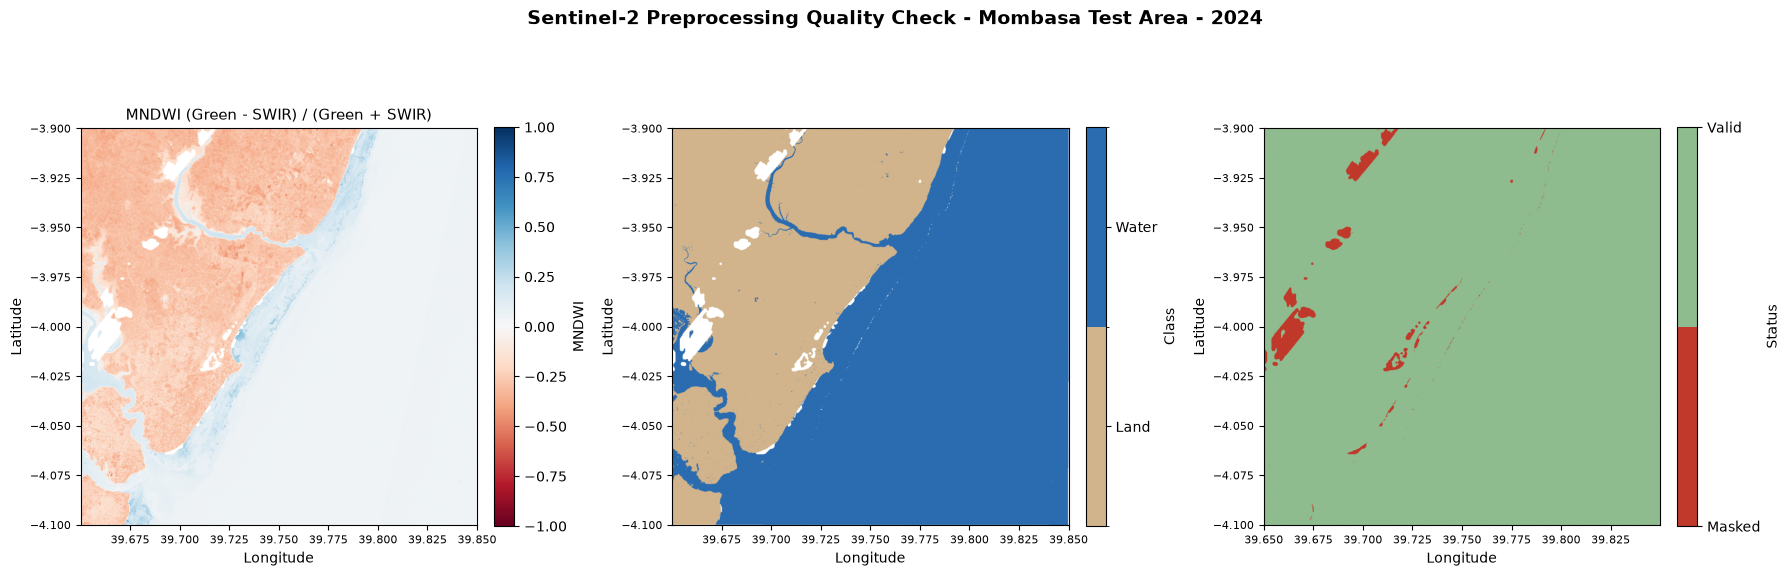

Saved QC figure to: c:\Users\pc\Documents\Data Science Projects\Shoremonitor\outputs\figures\mombasa_test_preprocessing_qc_2024.png


In [21]:
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap, BoundaryNorm
from pyproj import Transformer

# --- Helper: lon/lat extent for readable axis labels --------------------------
def lonlat_extent(da):
    """Return [left, right, bottom, top] in lon/lat from a projected DataArray."""
    transformer = Transformer.from_crs(da.rio.crs, "EPSG:4326", always_xy=True)
    minx, miny, maxx, maxy = da.rio.bounds()
    left, bottom = transformer.transform(minx, miny)
    right, top = transformer.transform(maxx, maxy)
    return [left, right, bottom, top]


# --- Output directory ---------------------------------------------------------
FIG_DIR = PROJECT_ROOT / "outputs" / "figures"
FIG_DIR.mkdir(parents=True, exist_ok=True)

# --- Colormaps ----------------------------------------------------------------
# Water mask: 0 = land (tan), 1 = water (blue), NaN = invalid (white).
water_cmap = ListedColormap(["#d2b48c", "#2b6cb0"])
water_cmap.set_bad(color="white")
water_norm = BoundaryNorm([-0.5, 0.5, 1.5], water_cmap.N)

# Valid mask: 0 = masked (red), 1 = valid (light green).
valid_cmap = ListedColormap(["#c0392b", "#8fbc8f"])

# --- Build the figure ---------------------------------------------------------
fig, axes = plt.subplots(1, 3, figsize=(18, 6))

# Panel 1: MNDWI
im0 = axes[0].imshow(
    mndwi.values, cmap="RdBu", vmin=-1.0, vmax=1.0, extent=lonlat_extent(mndwi)
)
axes[0].set_title("MNDWI (Green - SWIR) / (Green + SWIR)")
fig.colorbar(im0, ax=axes[0], fraction=0.046, pad=0.04, label="MNDWI")

# Panel 2: Water mask
im1 = axes[1].imshow(
    water_mask.values,
    cmap=water_cmap,
    norm=water_norm,
    extent=lonlat_extent(water_mask),
)
cbar1 = fig.colorbar(
    im1, ax=axes[1], fraction=0.046, pad=0.04, ticks=[0, 1], label="Class"
)
cbar1.ax.set_yticklabels(["Land", "Water"])

# Panel 3: Valid-pixel mask
valid_u8 = valid_mask.astype("uint8").values
im2 = axes[2].imshow(
    valid_u8, cmap=valid_cmap, vmin=0, vmax=1, extent=lonlat_extent(valid_mask)
)
cbar2 = fig.colorbar(
    im2, ax=axes[2], fraction=0.046, pad=0.04, ticks=[0, 1], label="Status"
)
cbar2.ax.set_yticklabels(["Masked", "Valid"])

# --- Labels and overall title -------------------------------------------------
for ax, name in zip(axes, ["MNDWI", "Water mask", "Valid-pixel mask"]):
    ax.set_xlabel("Longitude")
    ax.set_ylabel("Latitude")
    ax.set_title(ax.get_title(), fontsize=11)
    ax.tick_params(labelsize=8)

fig.suptitle(
    "Sentinel-2 Preprocessing Quality Check - Mombasa Test Area - 2024",
    fontsize=14,
    fontweight="bold",
)
fig.tight_layout(rect=[0, 0, 1, 0.96])

# --- Save ---------------------------------------------------------------------
qc_figure_path = FIG_DIR / "mombasa_test_preprocessing_qc_2024.png"
fig.savefig(qc_figure_path, dpi=150, bbox_inches="tight")
plt.show()
print("Saved QC figure to:", qc_figure_path)


- **MNDWI panel** — open water should read as strongly positive (red),
  land as near-zero or negative (blue/white). Look for odd patches that may
  be **turbid / sediment-laden water** (weaker signal) or **wet sand**.
- **Water mask panel** — the water body should look coherent and follow the
  coastline. Watch for:
  - **cloud contamination** or leftover bright pixels misclassified as water,
  - **shadow** along clouds/headlands creating false water or false land,
  - **turbid water** near river mouths/ports slipping below the threshold,
  - **incorrect water/land classification** along piers and the shoreline.
- **Valid-pixel mask panel** — red gaps are clouds/shadows/no-data that were
  correctly excluded; large red regions over the sea mean fewer usable pixels.

The `0.0` threshold is only an initial guess. **Open
`water_mask_2024.tif` in QGIS** (overlay it on the true-colour imagery) for a
closer look and adjust the threshold before moving on to **shoreline
extraction in the next notebook**.